In [1]:
import numpy as np
import pandas as pd
import pathlib
from stl import mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import sys
sys.path.append("..")

import multipoles as mt
import micromag as mg
from micromag import MICROMETER_TO_METER, TESLA_TO_NANOTESLA

In [2]:
figure_dir= pathlib.Path("../../paper/figures")
data_dir = pathlib.Path("../..") / "data/micromag_models/spheric_shells"
stl_dir = pathlib.Path("../..") / "data/micromag_models/STL_ellipsoids"

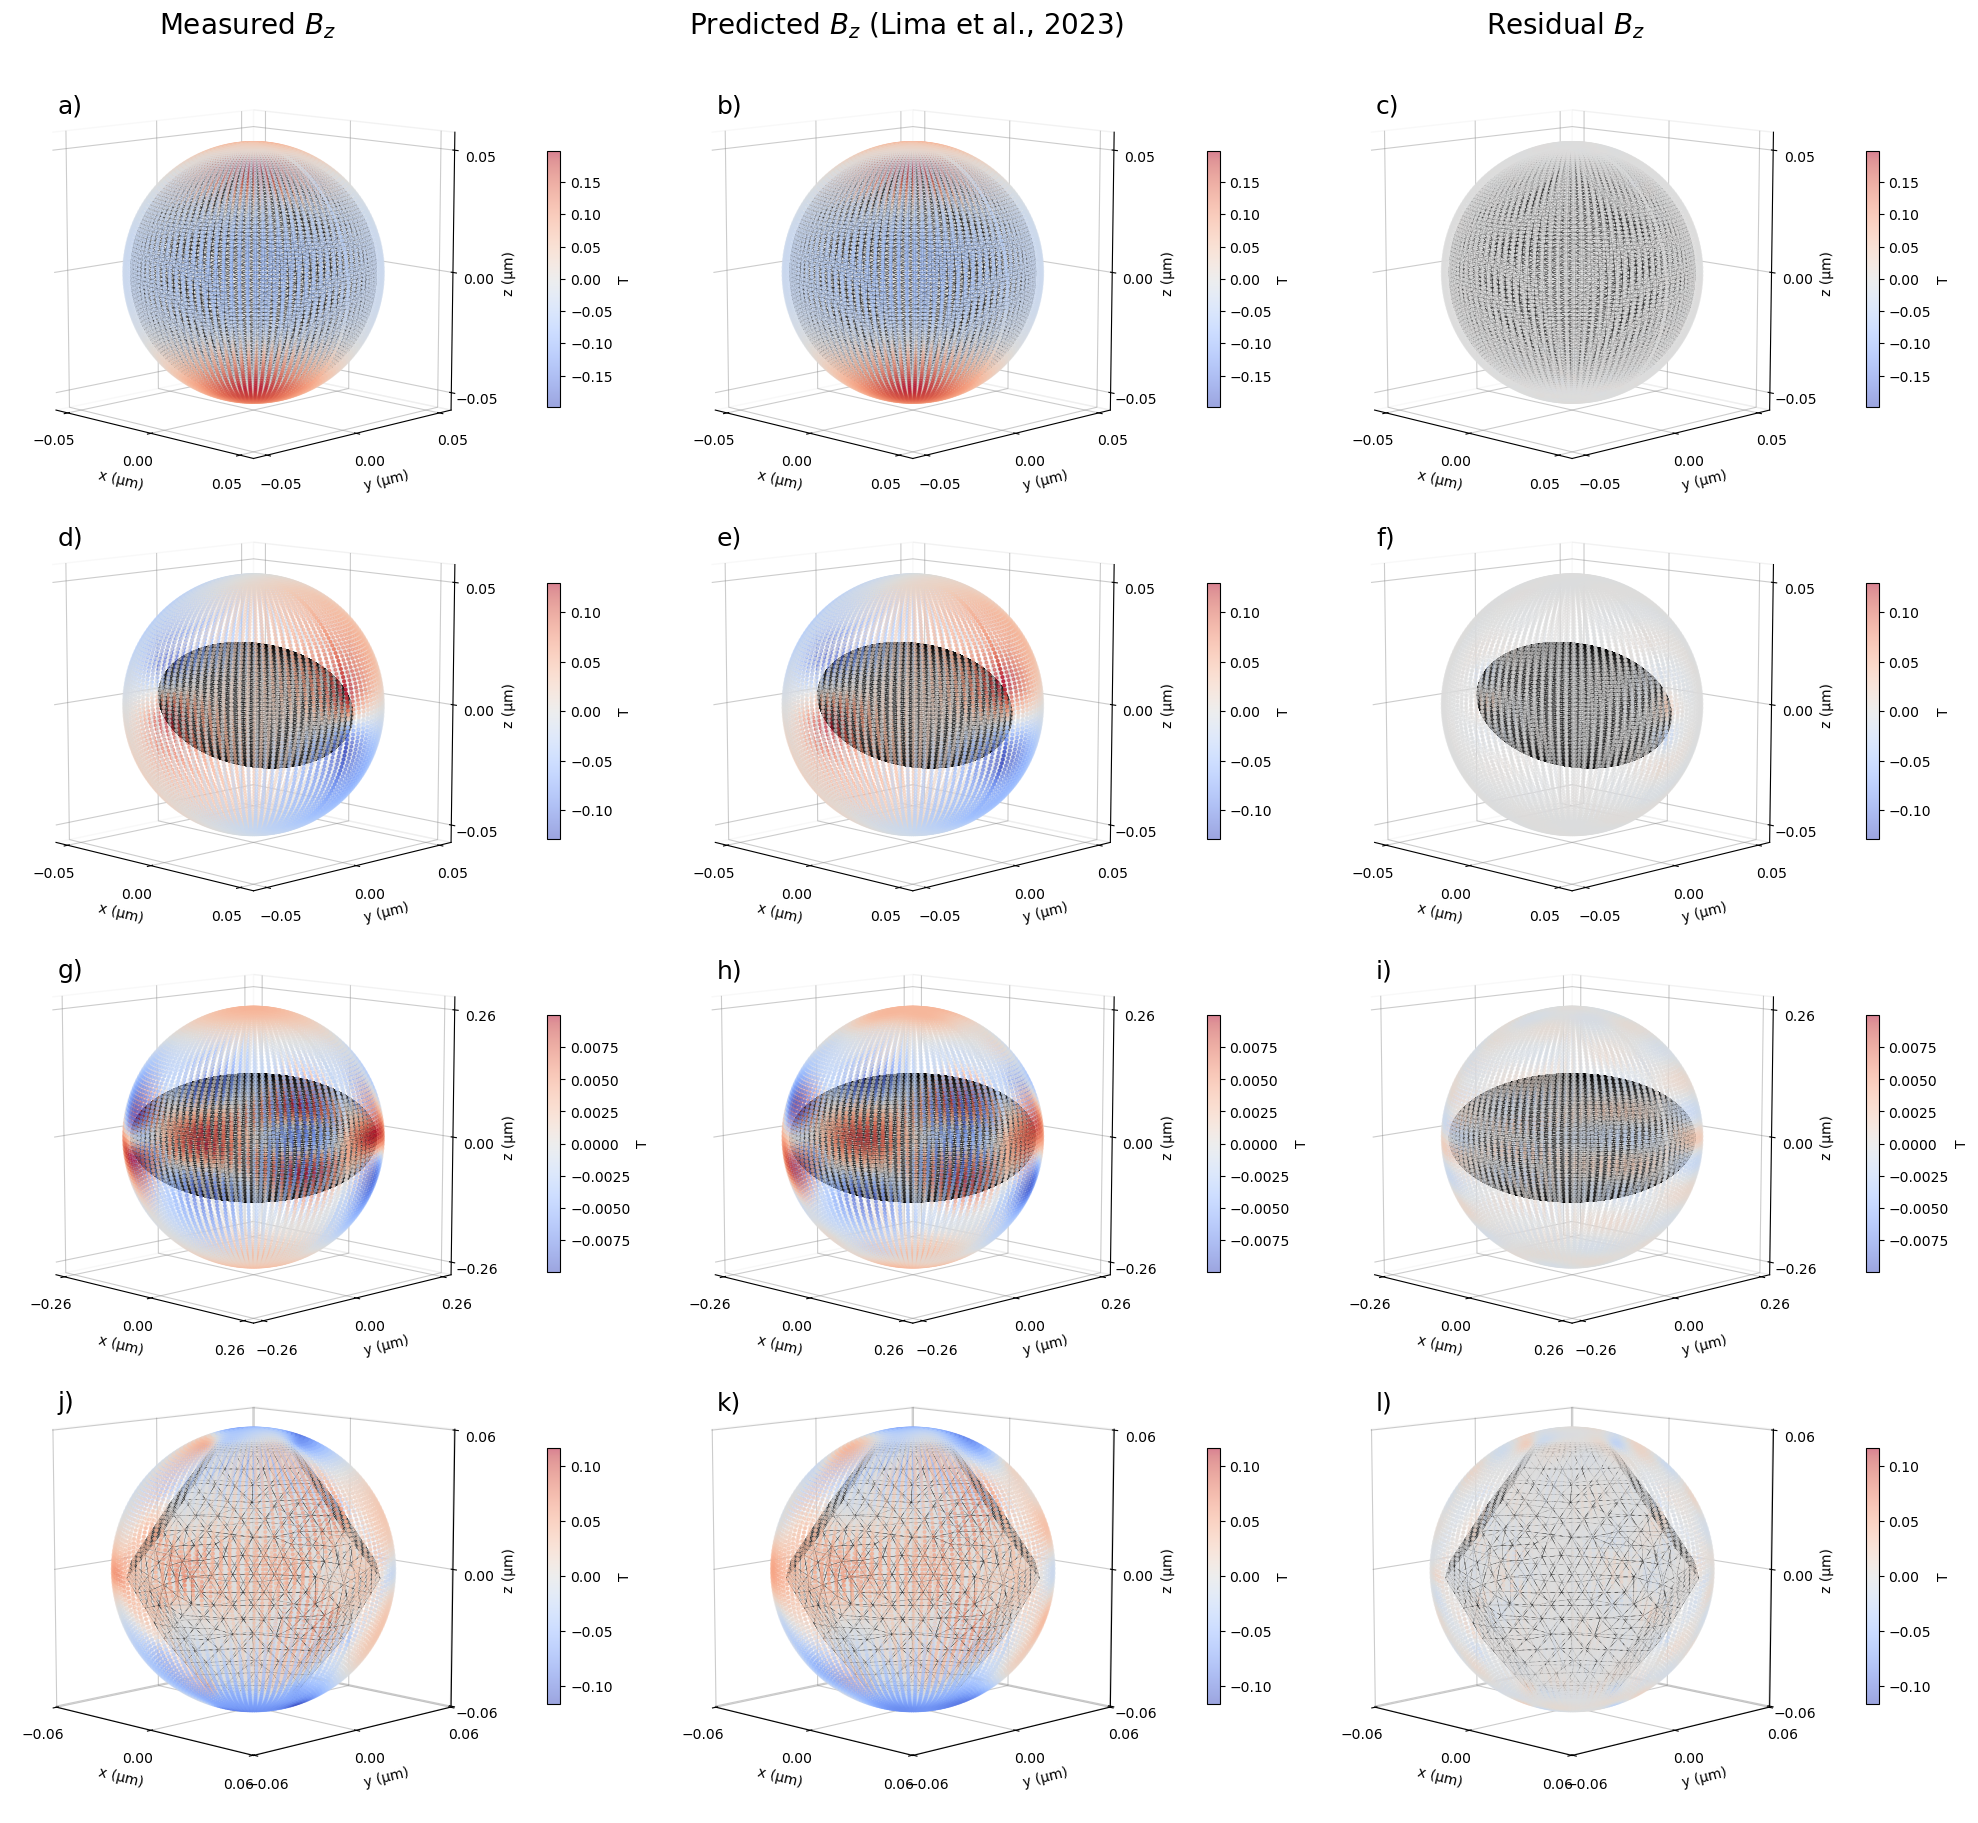

In [3]:
filenames = [
    "eps1.csv",    # sphere
    "eps6.csv",    # prolate
    "eps12.csv",   # oblate
    "eps16.csv",    # euhedral
]

stl_filenames = [
    "eps1.stl",
    "eps6.stl",
    "eps12.stl",
    "eps16.stl",
]

titles = ["Measured $B_z$", "Predicted $B_z$ (Lima et al., 2023)", "Residual $B_z$"]
letters = "abcdefghijkl"

fig = plt.figure(figsize=(20, 20), facecolor='none')
all_axes = []

for row, (csv_file, stl_file) in enumerate(zip(filenames, stl_filenames)):
    # === 1. Load CSV data ===
    df = pd.read_csv(data_dir / csv_file)
    x = df["x"].values * 1.0e-6
    y = df["y"].values * 1.0e-6
    z = df["z"].values * -1.0e-6
    bz = df["bz"].values * 1.0e-9

    coordinates = (x, y, z)

    location = np.array([0,0,0])
    sph = mt.SphericalHarmonicsBz(location, damping=1e-1, min_degree=1, max_degree=10).fit(coordinates, bz)
    
    bz_pred = sph.predict(coordinates)


    bz_pred = bz_pred
    residual = bz - bz_pred

    # === 4. Common colorbar
    scale = max(abs(bz).max(), abs(bz_pred).max(), abs(residual).max())
    vmin, vmax = -scale, scale
    datasets = [bz, bz_pred, residual]

    # === 5. Column loop (obs, pred, residual)
    for col in range(3):
        idx = row * 3 + col + 1
        ax = fig.add_subplot(4, 3, idx, projection='3d')
        all_axes.append(ax)

        # Transparência e grid
        ax.patch.set_alpha(0.0)
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        ax.grid(True)
        ax.xaxis._axinfo["grid"]['color'] = (0.5, 0.5, 0.5, 0.4)
        ax.yaxis._axinfo["grid"]['color'] = (0.5, 0.5, 0.5, 0.4)
        ax.zaxis._axinfo["grid"]['color'] = (0.5, 0.5, 0.5, 0.4)

        # Ticks
        ax.set_xticks(np.round(np.linspace(x.min()*1e6, x.max()*1e6, 3), 2))
        ax.set_yticks(np.round(np.linspace(y.min()*1e6, y.max()*1e6, 3), 2))
        ax.set_zticks(np.round(np.linspace(z.min()*1e6, z.max()*1e6, 3), 2))

        # Bz Field
        p = ax.scatter(
            x * 1e6, y * 1e6, z * 1e6,
            c=datasets[col], cmap="coolwarm", s=4,
            vmin=vmin, vmax=vmax, alpha=0.5
        )

        if row == 0:
            ax.set_title(titles[col], fontsize=20)
        ax.set_xlabel("x (µm)")
        ax.set_ylabel("y (µm)")
        ax.set_zlabel("z (µm)")
        fig.colorbar(p, ax=ax, shrink=0.4, label="T", orientation='vertical', pad=0.1)

        ax.text2D(0.1, 0.85, f"{letters[idx - 1]})", transform=ax.transAxes, fontsize=18)
        ax.set_aspect("equal")
        ax.view_init(elev=10, azim=-45)

        # === 6. Load STL files ===
        stl_path = stl_dir / stl_file
        if stl_path.exists():
            m = mesh.Mesh.from_file(str(stl_path))
            stl_poly = Poly3DCollection(
                m.vectors,
                edgecolor='k',
                facecolor='lightgrey',
                linewidths=0.2,
                alpha=0.5
            )
            ax.add_collection3d(stl_poly)

            # Adjust the scale (using the STL bounding box)
            pts = m.points.flatten()
            ax.auto_scale_xyz(pts, pts, -pts)  # negative Z for CSV

# === Finalização ===
fig.patch.set_alpha(0.0)
plt.tight_layout(h_pad=-15)
plt.savefig(figure_dir / "particles_spherical_harmonic_fitting.png", dpi=300,
            bbox_inches="tight", transparent=True)
plt.show()